# Progress report, 2026-10-17

Purpose/risk claims for every DSLD label, what they add to iDISK 2.0, how they will be
evaluated, and what comes next.

**In short**
- Claims were extracted from **all 214,780 DSLD labels**, with no failures: 466,630 purpose and
  355,134 risk items, about 98% of them verbatim from the label.
- The main run **finished on 15 Oct** after **42.6 hours** (13 Oct 18:22 to 15 Oct 13:00 UTC),
  averaging **74 generated tokens/s** overall (4 requests in parallel, 18.6 tok/s per request).
  It got 214,773 labels right first time. The other 7 had outputs too long for the output-token
  limit, so on 16 Oct they were rerun with a longer limit, and all 7 came back ok.
- iDISK 2.0 has almost no Purpose/Risk for DSLD products, and its effect relations
  (*is effective for*, *has adverse reaction*) come **only from MSKCC**. These claims are
  what will fill that gap.
- Next: evaluate the extraction, then attribute each claim to an ingredient and turn the
  claims into relations.

This notebook only reads files: the finished run, the iDISK 2.0 release and the numbers
from `docs/extraction-quality-check.md`. It needs no GPU and no model.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import FancyBboxPatch

from engine.repositories.dsld.labels import loader as label_sets
from engine.repositories.dsld.runs import loader as runs
from engine.repositories.dsld.runs import paths as run_paths
from engine.services.sources.dsld import parse_dsld_ids

RUN = run_paths.RUNS_ROOT / "full214780-r4-2610131822-0"
IDISK = run_paths.REPO_ROOT / "datasets" / "iDISK2.0" / "Data"

# Reference palette (validated light-mode categorical slots 1-3) plus neutrals.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED, EMPTY, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#d6d5d0", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10.5,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": EMPTY, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": False, "legend.frameon": False,
})


def label_bars(ax, bars, fmt, inside=False):
    """Writes each bar's value at its end, in text ink."""
    for b in bars:
        w = b.get_width()
        ax.text(w, b.get_y() + b.get_height() / 2, "  " + fmt(w),
                va="center", ha="left", color=INK, fontsize=10)


def label_pct_count(ax, bars, counts, digits=1):
    """Writes "pct%  (count)" at each bar's end, for bars drawn from percentages."""
    for b, n in zip(bars, counts):
        ax.text(b.get_width(), b.get_y() + b.get_height() / 2,
                f"  {b.get_width():.{digits}f}%  ({n:,})",
                va="center", ha="left", color=INK, fontsize=10)

## 1. Where the pipeline stands

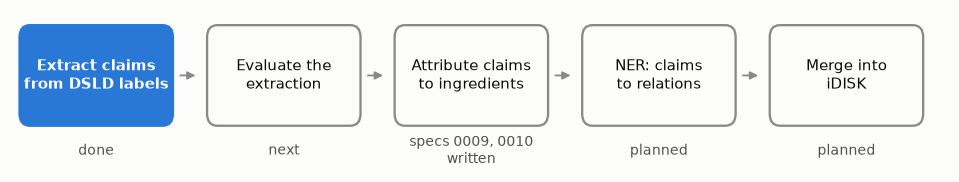

In [2]:
steps = [
    ("Extract claims\nfrom DSLD labels", "done", BLUE),
    ("Evaluate the\nextraction", "next", None),
    ("Attribute claims\nto ingredients", "specs 0009, 0010\nwritten", None),
    ("NER: claims\nto relations", "planned", None),
    ("Merge into\niDISK", "planned", None),
]
fig, ax = plt.subplots(figsize=(11, 1.9))
ax.set_xlim(0, len(steps) * 2.2); ax.set_ylim(0, 1.6); ax.axis("off")
for i, (name, state, fill) in enumerate(steps):
    x = i * 2.2 + 0.1
    ax.add_patch(FancyBboxPatch((x, 0.45), 1.8, 1.0, boxstyle="round,pad=0,rounding_size=0.12",
                                fc=fill or SURFACE, ec=fill or MUTED, lw=1.5))
    ax.text(x + 0.9, 0.95, name, ha="center", va="center", fontsize=10,
            color="white" if fill else INK, weight="bold" if fill else None)
    ax.text(x + 0.9, 0.2, state, ha="center", va="center", fontsize=9, color=INK_2)
    if i < len(steps) - 1:
        ax.annotate("", xy=(x + 2.1, 0.95), xytext=(x + 1.85, 0.95),
                    arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.2))
plt.show()

## 2. The extraction finished on every label

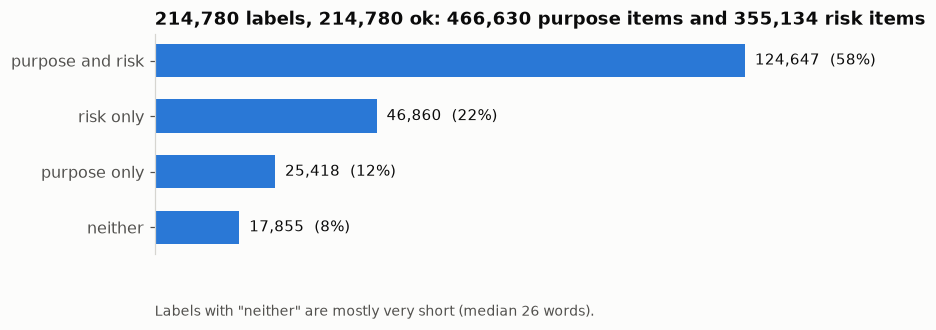

In [3]:
df = pd.DataFrame(runs.read_rows(RUN))
df["has_p"] = df.purpose.str.len() > 0
df["has_r"] = df.risk.str.len() > 0
n_p, n_r = df.purpose.str.len().sum(), df.risk.str.len().sum()

groups = pd.Series({
    "purpose and risk": (df.has_p & df.has_r).sum(),
    "risk only": (~df.has_p & df.has_r).sum(),
    "purpose only": (df.has_p & ~df.has_r).sum(),
    "neither": (~df.has_p & ~df.has_r).sum(),
})

fig, ax = plt.subplots(figsize=(9, 2.6))
bars = ax.barh(groups.index[::-1], groups.values[::-1], color=BLUE, height=0.6)
label_bars(ax, bars, lambda w: f"{w:,.0f}  ({w / len(df):.0%})")
ax.set_xlim(0, groups.max() * 1.3); ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title(f"{len(df):,} labels, {(df.status == 'ok').sum():,} ok: "
             f"{n_p:,} purpose items and {n_r:,} risk items")
ax.text(0, -0.28, "Labels with \"neither\" are mostly very short (median 26 words).",
        transform=ax.transAxes, color=INK_2, fontsize=9)
plt.show()

In [ ]:
# Run status and speed. The main run's first pass cut 7 labels off at the output-token
# limit (failed_checks); a second run on 16 Oct with a longer limit redid only those 7 and
# its rows replaced theirs here, so they carry that run's config hash. Start and end times
# are from the "run finished" notifications; the run files don't record them.
from datetime import datetime, timezone

MAIN_START = datetime(2026, 10, 13, 18, 22, tzinfo=timezone.utc)
MAIN_END = datetime(2026, 10, 15, 13, 0, 9, tzinfo=timezone.utc)
RERUN = "full214780-r4-2610160915-0"

main_hash = runs.read_manifest(RUN)["config_hash"]
main, redone = df[df.config_hash == main_hash], df[df.config_hash != main_hash]
wall_s = (MAIN_END - MAIN_START).total_seconds()
n_out, n_in = main.completion_tokens.sum(), main.prompt_tokens.sum()

print(f"Status now: {df.status.value_counts().to_dict()}")
print(f"Main run: {MAIN_START:%d %b %H:%M} to {MAIN_END:%d %b %H:%M} UTC = {wall_s / 3600:.1f} h, "
      f"{len(main):,} ok, {len(redone)} cut off at the output limit")
print(f"Rerun {RERUN}: {len(redone)} ok, {redone.completion_tokens.min():,}-"
      f"{redone.completion_tokens.max():,} output tokens, {redone.latency_ms.sum() / 1000:.0f} s of generation")
print(f"Main run tokens: {n_in:,} read, {n_out:,} generated ({len(main) / wall_s:.2f} labels/s)")
print(f"Average speed: {n_out / wall_s:.1f} generated tok/s overall "
      f"({(n_in + n_out) / wall_s:,.0f} tok/s with prompt reading); "
      f"{n_out / (main.latency_ms.sum() / 1000):.1f} generated tok/s per request")

## 3. Almost every item is copied verbatim from the label

An item is meant to be a verbatim piece of the label text. The checks below are
deterministic and run over every item. Being verbatim shows the model didn't invent the
item, but not that it is a correct claim: that is what the evaluation in section 5 checks.
Overlap metrics (BLEU, ROUGE, BERTScore) are not used: they are trivially perfect for
verbatim items.

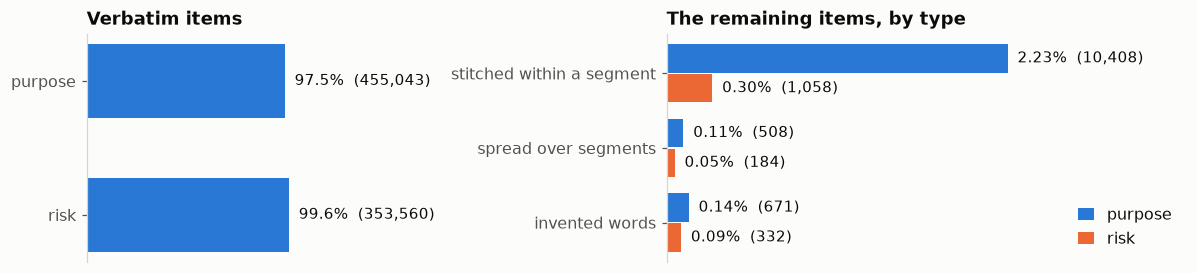

In [4]:
# Each item's faithfulness type, against the passage the model read. A segment is one
# line of the passage (one statement or ingredient note); words are split on whitespace.
TYPES = ["verbatim", "stitched within a segment", "spread over segments", "invented words"]
_, labels = label_sets.load_flattened(runs.read_manifest(RUN)["label_set"])

kinds = {"purpose": [], "risk": []}
for row in df.itertuples():
    text = labels[row.dsld_id].passage
    segments = [set(s.split()) for s in text.split("\n")]
    words = set(text.split())
    for kind in kinds:
        for item in getattr(row, kind):
            t = item["text"]
            if t in text:
                kinds[kind].append(TYPES[0])
            elif any(all(w in s for w in t.split()) for s in segments):
                kinds[kind].append(TYPES[1])
            elif all(w in words for w in t.split()):
                kinds[kind].append(TYPES[2])
            else:
                kinds[kind].append(TYPES[3])
type_counts = pd.DataFrame({k: pd.Series(v).value_counts() for k, v in kinds.items()}).reindex(TYPES).fillna(0).astype(int)
faith = type_counts / type_counts.sum() * 100

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 2.6), gridspec_kw={"width_ratios": [1, 1.6]})
bars = a.barh(["risk", "purpose"], faith.loc["verbatim", ["risk", "purpose"]], color=BLUE, height=0.55)
label_pct_count(a, bars, type_counts.loc["verbatim", ["risk", "purpose"]])
a.set_xlim(0, 160); a.set_xticks([]); a.spines["bottom"].set_visible(False)
a.set_title("Verbatim items")

rest = faith.drop("verbatim")[::-1]
y = range(len(rest))
for off, kind, color in [(0.2, "purpose", BLUE), (-0.2, "risk", ORANGE)]:
    bars = b.barh([i + off for i in y], rest[kind], height=0.38, color=color, label=kind)
    label_pct_count(b, bars, type_counts.drop("verbatim")[::-1][kind], digits=2)
b.set_yticks(list(y), rest.index); b.set_xlim(0, 3.4); b.set_xticks([])
b.spines["bottom"].set_visible(False)
b.legend(loc="lower right", handlelength=1)
b.set_title("The remaining items, by type")
fig.tight_layout(); plt.show()

## 4. What this adds to iDISK 2.0

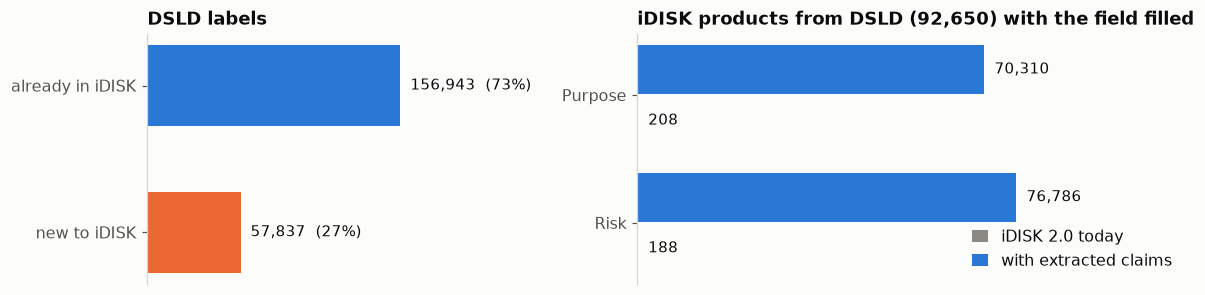

In [5]:
dsp = pd.read_csv(IDISK / "Entity" / "DSP.csv", dtype=str,
                  usecols=["iDISK_ID", "NHP_ID", "DSLD_ID", "Purpose", "Risk"])
dsld_rows = dsp[dsp.DSLD_ID.notna()].copy()
dsld_rows["ids"] = dsld_rows.DSLD_ID.apply(lambda c: {int(x) for x in parse_dsld_ids(c)})
in_idisk = set().union(*dsld_rows.ids)

ids_p = set(df.dsld_id[df.has_p])
ids_r = set(df.dsld_id[df.has_r])
known = df.dsld_id.isin(in_idisk)

fill = pd.DataFrame({
    "iDISK 2.0 today": [dsld_rows.Purpose.notna().sum(), dsld_rows.Risk.notna().sum()],
    "with extracted claims": [
        (dsld_rows.Purpose.notna() | dsld_rows.ids.apply(lambda s: bool(s & ids_p))).sum(),
        (dsld_rows.Risk.notna() | dsld_rows.ids.apply(lambda s: bool(s & ids_r))).sum(),
    ],
}, index=["Purpose", "Risk"])

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 2.8), gridspec_kw={"width_ratios": [1, 1.4]})
counts = pd.Series({"new to iDISK": (~known).sum(), "already in iDISK": known.sum()})
bars = a.barh(counts.index, counts.values, color=[ORANGE, BLUE], height=0.55)
label_bars(a, bars, lambda w: f"{w:,.0f}  ({w / len(df):.0%})")
a.set_xlim(0, counts.max() * 1.55); a.set_xticks([]); a.spines["bottom"].set_visible(False)
a.set_title("DSLD labels")

y = range(len(fill))
for off, col, color in [(0.2, "iDISK 2.0 today", MUTED), (-0.2, "with extracted claims", BLUE)]:
    bars = b.barh([i + off for i in y], fill[col], height=0.38, color=color, label=col)
    label_bars(b, bars, lambda w: f"{w:,.0f}")
b.set_yticks(list(y), fill.index); b.invert_yaxis()
b.set_xlim(0, len(dsld_rows) * 1.2); b.set_xticks([]); b.spines["bottom"].set_visible(False)
b.legend(loc="lower right", handlelength=1)
b.set_title(f"iDISK products from DSLD ({len(dsld_rows):,}) with the field filled")
fig.tight_layout(); plt.show()

iDISK fills Purpose/Risk only from the Canadian LNHPD, so its DSLD products almost
never have them. The new labels also add products that iDISK doesn't have at all.

### The relation gap: effect relations come only from MSKCC

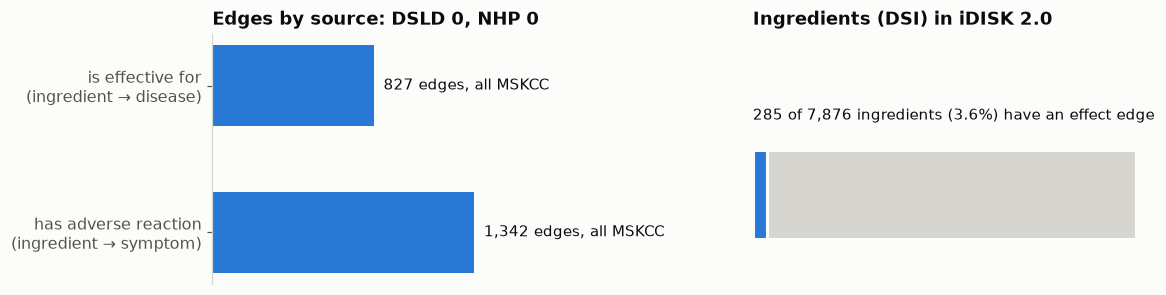

Text that could become effect edges: 821,764 DSLD claims, plus 65,097 NHP products whose Purpose is free text on the product today.


In [6]:
dsi = pd.read_csv(IDISK / "Entity" / "DSI.csv", usecols=["iDISK_ID", "MSKCC_Name"])
rel = {
    "is effective for\n(ingredient → disease)": pd.read_csv(IDISK / "Relation" / "dsi_dis.csv"),
    "has adverse reaction\n(ingredient → symptom)": pd.read_csv(IDISK / "Relation" / "dsi_ss.csv"),
}
by_source = pd.DataFrame({k: r.Source.value_counts() for k, r in rel.items()}).fillna(0).astype(int)
with_edge = set().union(*(set(r.DSI) for r in rel.values()))

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 2.8), gridspec_kw={"width_ratios": [1.3, 1]})
names = list(rel)[::-1]
bars = a.barh(names, [by_source.loc["MSKCC", n] for n in names], color=BLUE, height=0.55)
label_bars(a, bars, lambda w: f"{w:,.0f} edges, all MSKCC")
a.set_xlim(0, by_source.values.max() * 2); a.set_xticks([]); a.spines["bottom"].set_visible(False)
a.set_title("Edges by source: DSLD 0, NHP 0")

parts = pd.Series({"with ≥1 effect edge": len(with_edge), "with none": len(dsi) - len(with_edge)})
left = 0
for (name, v), color in zip(parts.items(), [BLUE, EMPTY]):
    b.barh([0], [v], left=left, color=color, height=0.5, edgecolor=SURFACE, linewidth=2)
    left += v
b.text(0, 0.42, f"{len(with_edge):,} of {len(dsi):,} ingredients ({len(with_edge) / len(dsi):.1%}) have an effect edge",
       color=INK, fontsize=10)
b.set_ylim(-0.5, 0.9); b.set_yticks([]); b.set_xticks([]); b.spines[["left", "bottom"]].set_visible(False)
b.set_title("Ingredients (DSI) in iDISK 2.0")
fig.tight_layout(); plt.show()

nhp_p = dsp.NHP_ID.notna() & dsp.Purpose.notna()
print(f"Text that could become effect edges: {n_p + n_r:,} DSLD claims, "
      f"plus {nhp_p.sum():,} NHP products whose Purpose is free text on the product today.")

Every *is effective for* and *has adverse reaction* edge comes from MSKCC, which covers only
a few hundred ingredients. DSLD and NHP contribute none: their claims are text on the product,
and nothing links them to an ingredient. Attributing claims to ingredients (specs 0009/0010)
and then running NER over them is how these two relations get extended.

## 5. Evaluation plan

Two questions: is each item **faithful** to the label, and is it in the **right bucket**
(a real purpose, a real risk, or neither)?

- **Precision**, per item: from a sample stratified by the four item types of section 3,
  100 items per type for purposes and for risks, reweighted afterwards. A plain random
  sample would be almost all verbatim. Errors are split into *not a claim*,
  *wrong bucket* and *unfaithful*.
- **False negative and false positive rates**, per label: from a sample stratified by the
  four groups, with the same number of labels per group, reweighted afterwards. A label's
  group decides which errors it can show (below).
- Every rate is reported with a 95% confidence interval.

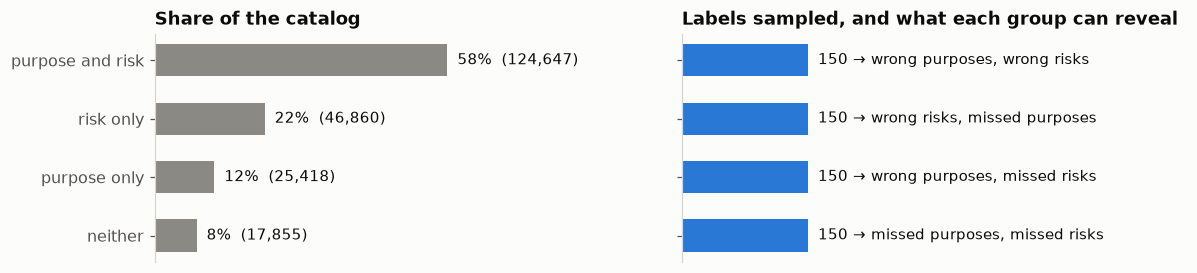

In [7]:
can_show = {
    "purpose and risk": "wrong purposes, wrong risks",
    "risk only": "wrong risks, missed purposes",
    "purpose only": "wrong purposes, missed risks",
    "neither": "missed purposes, missed risks",
}
share = groups / groups.sum() * 100
sample = pd.Series(150, index=groups.index)

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 2.6), sharey=True)
bars = a.barh(groups.index[::-1], share[::-1], color=MUTED, height=0.55)
label_pct_count(a, bars, groups[::-1], digits=0)
a.set_xlim(0, 100); a.set_xticks([]); a.spines["bottom"].set_visible(False)
a.set_title("Share of the catalog")
bars = b.barh(groups.index[::-1], sample[::-1], color=BLUE, height=0.55)
for bar, g in zip(bars, groups.index[::-1]):
    b.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f"  150 → {can_show[g]}",
           va="center", color=INK, fontsize=9.5)
b.set_xlim(0, 600); b.set_xticks([]); b.spines["bottom"].set_visible(False)
b.set_title("Labels sampled, and what each group can reveal")
fig.tight_layout(); plt.show()

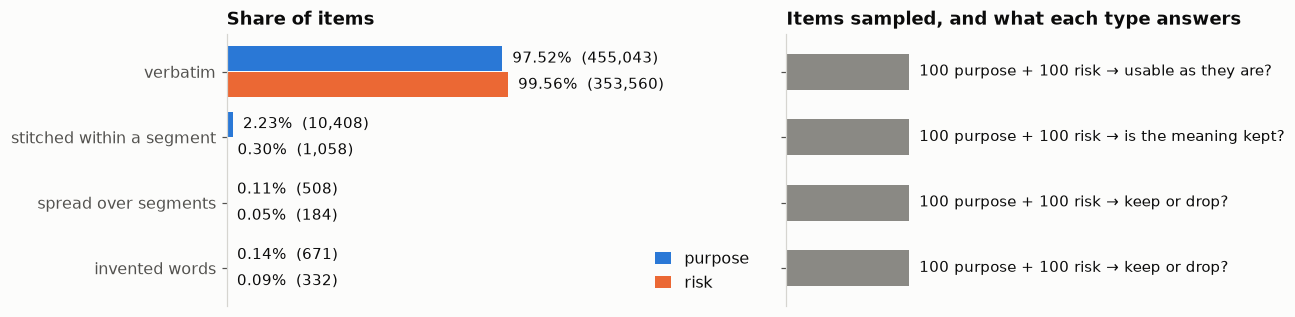

In [8]:
answers = {
    "verbatim": "usable as they are?",
    "stitched within a segment": "is the meaning kept?",
    "spread over segments": "keep or drop?",
    "invented words": "keep or drop?",
}
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3), sharey=True, gridspec_kw={"width_ratios": [1.25, 1]})
y = range(len(TYPES))
for off, kind, color in [(0.2, "purpose", BLUE), (-0.2, "risk", ORANGE)]:
    bars = a.barh([i + off for i in y], faith.loc[TYPES[::-1], kind], height=0.38, color=color, label=kind)
    label_pct_count(a, bars, type_counts.loc[TYPES[::-1], kind], digits=2)
a.set_yticks(list(y), TYPES[::-1]); a.set_xlim(0, 190); a.set_xticks([])
a.spines["bottom"].set_visible(False)
a.legend(loc="lower right", handlelength=1)
a.set_title("Share of items")
bars = b.barh(list(y), [200] * len(TYPES), color=MUTED, height=0.55)
for bar, t in zip(bars, TYPES[::-1]):
    b.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
           f"  100 purpose + 100 risk → {answers[t]}", va="center", color=INK, fontsize=9.5)
b.set_xlim(0, 700); b.set_xticks([]); b.spines["bottom"].set_visible(False)
b.set_title("Items sampled, and what each type answers")
fig.tight_layout(); plt.show()

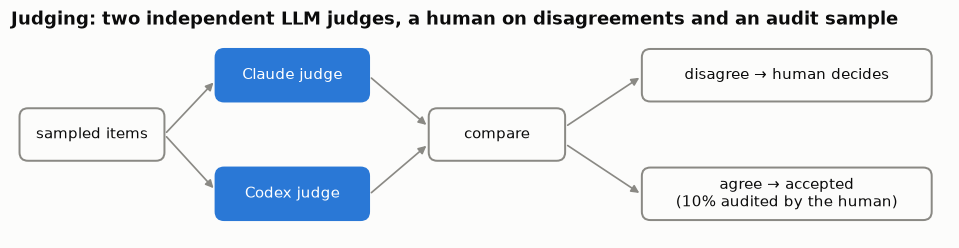

In [9]:
fig, ax = plt.subplots(figsize=(11, 2.4))
ax.set_xlim(0, 11); ax.set_ylim(0, 2.4); ax.axis("off")

def box(x, y, w, text, fill=None):
    ax.add_patch(FancyBboxPatch((x, y), w, 0.62, boxstyle="round,pad=0,rounding_size=0.1",
                                fc=fill or SURFACE, ec=fill or MUTED, lw=1.3))
    ax.text(x + w / 2, y + 0.31, text, ha="center", va="center", fontsize=9.5,
            color="white" if fill else INK)

def arrow(x0, y0, x1, y1, label=None):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.1))
    if label:
        ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.1, label, ha="center", fontsize=9, color=INK_2)

box(0.1, 0.9, 1.7, "sampled items")
box(2.4, 1.6, 1.8, "Claude judge", BLUE)
box(2.4, 0.2, 1.8, "Codex judge", BLUE)
box(4.9, 0.9, 1.6, "compare")
box(7.4, 1.6, 3.4, "disagree → human decides")
box(7.4, 0.2, 3.4, "agree → accepted\n(10% audited by the human)")
arrow(1.8, 1.21, 2.4, 1.85); arrow(1.8, 1.21, 2.4, 0.55)
arrow(4.2, 1.9, 4.9, 1.3); arrow(4.2, 0.5, 4.9, 1.1)
arrow(6.5, 1.3, 7.4, 1.9); arrow(6.5, 1.1, 7.4, 0.5)
ax.set_title("Judging: two independent LLM judges, a human on disagreements and an audit sample")
plt.show()

- A 50-item pilot fixes the rubric before the full judging.
- The judges are independent, and a judge that says a claim was missed has to quote the
  label. The quote is checked automatically.
- Judge reliability is reported as Cohen's κ between the judges, and between each judge
  and the human.

## 6. Next steps

1. **Evaluate the extraction:** the rubric pilot, then the full judged samples.
2. **Attribute DSLD claims to ingredients** (spec 0009). If a label has a single active
   ingredient, or the claim names one of its ingredients, the claim goes to that ingredient.
   Otherwise it stays on the product.
3. **Do the same for NHP products already in iDISK** (spec 0010). About 36.9k of them have
   exactly one medicinal ingredient.
4. **Define an iDISK 1.0-style staging format** (concepts, atoms, attributes, relations),
   so that new sources such as EU health claims and Australian TGA indications go through
   one shared integrator.
5. **Run NER over the attributed claims** to produce new *is effective for* and
   *has adverse reaction* edges from DSLD and NHP, beyond the MSKCC-only edges iDISK has now.